# Part 7 — Gamma Distribution for Demand Forecasting
**Demand Forecasting Masterclass · Lesson 7 of 12**

In Part 6, Poisson modeled counts, with mean equal to variance. Here we model positive demand magnitude with a continuous distribution whose mean and variance can vary independently. We will distinguish conditional positive demand from total monthly demand, derive the parameters, calculate probabilities and inventory quantiles, and build a bridge to Tweedie.

Run cells in order. Static charts are saved in the notebook. Optional interactive controls are at the end. Dependencies: `numpy pandas scipy matplotlib scikit-learn ipywidgets` (install with `%pip install ...` if necessary).

## 1. Why Gamma?
A positive demand quantity can be right-skewed: small orders may be common and very large orders rare. Gamma provides a flexible positive continuous distribution for such quantities, repair times and consumption measured in weight or volume.

| Distribution | Support | Main application |
|---|---|---|
| Poisson | 0, 1, 2, ... | Counts |
| Gamma | Positive real numbers | Positive magnitudes |
| Negative Binomial | 0, 1, 2, ... | Overdispersed counts |
| Tweedie ($1<p<2$) | Zero and positive real numbers | Aggregate demand with zeros |

Our spare parts are integer-valued, so Gamma is a continuous approximation, not an exact count model. Gamma cannot assign positive probability to an exact zero.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma, poisson
from scipy.special import gammaln, digamma
from scipy.optimize import brentq
from matplotlib.ticker import PercentFormatter
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True, 'grid.alpha':0.2, 'figure.dpi':110})
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
demand = np.array([10,0,0,12,0,8,0,0,15,0,10,0])
positive = demand[demand>0]
p_occ = len(positive)/len(demand)
mu = positive.mean()
v = positive.var(ddof=0)
lam = demand.mean()

## 2. Historical demand and two components
We retain all 12 months when calculating occurrence probability, but use only the five positive months for the conditional magnitude model.

$$q=P(Y>0)=5/12,\qquad E[W]=55/5=11$$
$$E[Y]=qE[W]=4.583333$$

Here $Y$ is monthly demand and $W$ is demand conditional on a positive month. These positive months are not necessarily individual orders.

,Month,Actual demand
0,Jan,10
1,Feb,0
2,Mar,0
3,Apr,12
4,May,0
5,Jun,8
6,Jul,0
7,Aug,0
8,Sep,15
9,Oct,0


Total                           55.000000
ADI                              2.400000
Positive mean                   11.000000
Positive sample variance         7.000000
Positive population variance     5.600000
Zero proportion                  0.583333
Monthly mean                     4.583333
dtype: float64

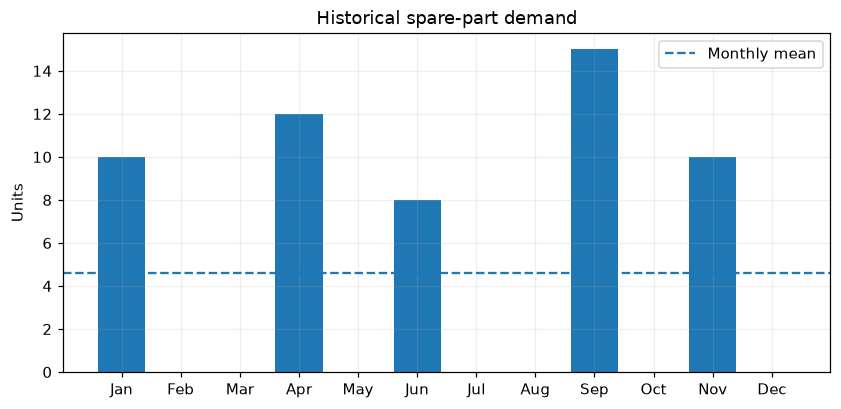

In [2]:
display(pd.DataFrame({'Month':months,'Actual demand':demand}))
display(pd.Series({'Total':demand.sum(),'ADI':len(demand)/len(positive),'Positive mean':mu,'Positive sample variance':positive.var(ddof=1),'Positive population variance':v,'Zero proportion':1-p_occ,'Monthly mean':lam}))
plt.bar(months,demand); plt.axhline(lam,ls='--',label='Monthly mean'); plt.ylabel('Units'); plt.title('Historical spare-part demand'); plt.legend(); plt.show()

## 3. Gamma parameters
Let $W\sim\operatorname{Gamma}(\alpha,\theta)$, where $\alpha>0$ is shape and $\theta>0$ is scale. Rate $\beta=1/\theta$ is an alternative parameterization.

$$E[W]=\alpha\theta,\qquad \operatorname{Var}(W)=\alpha\theta^2$$
$$E[W]=\alpha/\beta,\qquad \operatorname{Var}(W)=\alpha/\beta^2$$

Shape below 1 gives a decreasing density with a singularity at zero; shape 1 gives the exponential distribution; shape above 1 gives an interior mode $(\alpha-1)\theta$. Larger shape reduces relative skewness $2/\sqrt{\alpha}$. Increasing scale stretches the distribution.

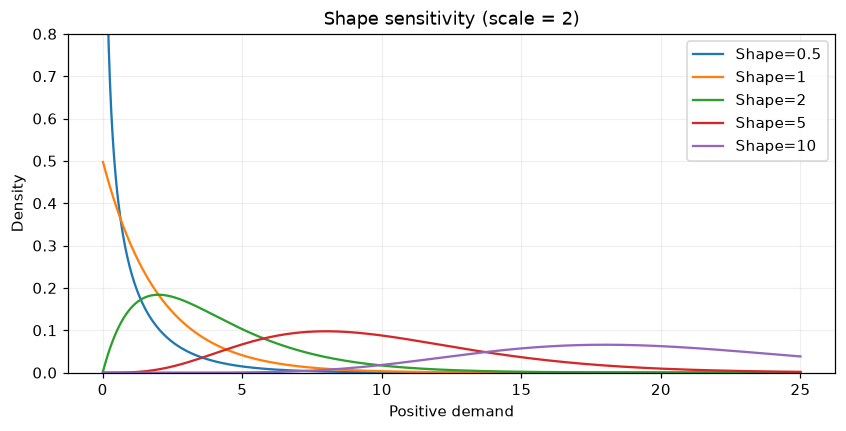

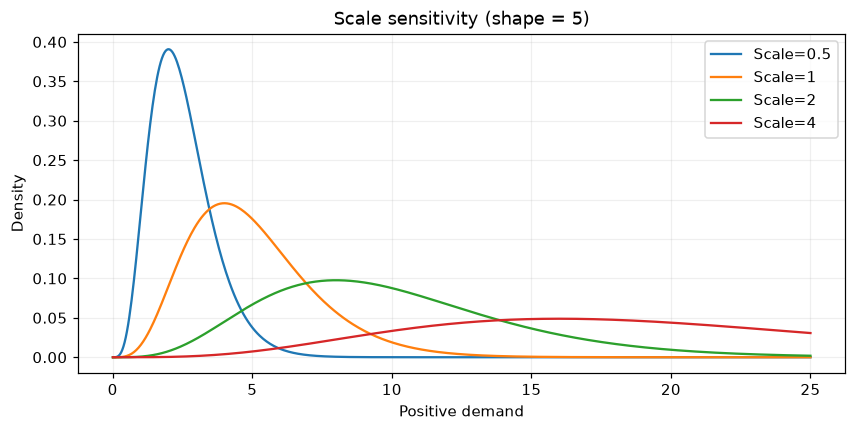

In [3]:
x=np.linspace(.01,25,600)
for a in [.5,1,2,5,10]: plt.plot(x,gamma.pdf(x,a,scale=2),label=f'Shape={a}')
plt.ylim(0,0.8); plt.xlabel('Positive demand'); plt.ylabel('Density'); plt.title('Shape sensitivity (scale = 2)'); plt.legend(); plt.show()
for t in [.5,1,2,4]: plt.plot(x,gamma.pdf(x,5,scale=t),label=f'Scale={t}')
plt.xlabel('Positive demand'); plt.ylabel('Density'); plt.title('Scale sensitivity (shape = 5)'); plt.legend(); plt.show()

## 4. Gamma function and PDF
$$\Gamma(\alpha)=\int_0^\infty t^{\alpha-1}e^{-t}\,dt$$
For positive integer $n$, $\Gamma(n)=(n-1)!$. For example, $\Gamma(3)=2$.

$$f(w)=\frac{w^{\alpha-1}e^{-w/\theta}}{\Gamma(\alpha)\theta^\alpha},\qquad w>0$$
Density is not probability. For continuous demand, $P(W=10)=0$; probabilities are areas under the curve. A density may exceed 1 without violating probability rules.

Manual example: shape 2, scale 3, evaluate at 6:
$$f(6)=\frac{6e^{-2}}{1\times9}=0.090224$$
For integer shape 2, $F(w)=1-e^{-w/3}(1+w/3)$, so $P(W\le6)=1-3e^{-2}\approx0.5940$.

In [4]:
print('Manual density:',6*np.exp(-2)/9)
print('SciPy density:',gamma.pdf(6,2,scale=3))
print('CDF:',gamma.cdf(6,2,scale=3))

Manual density: 0.0902235221577418
SciPy density: 0.0902235221577418
CDF: 0.5939941502901616


## 5. Method of Moments (MoM)
Match theoretical moments to empirical moments. The positive observations are 10, 12, 8, 15, 10.

$$\bar w=11$$
$$\sum(w_i-11)^2=1+1+9+16+1=28$$
$$m_2=28/5=5.6$$

We use divisor $n$ for conventional moment matching, not the unbiased sample variance (7).

Solve $\alpha\theta=11$ and $\alpha\theta^2=5.6$:
$$\hat\theta=m_2/\bar w=0.509091$$
$$\hat\alpha=\bar w^2/m_2=21.607143$$
$$\hat\beta=1/\hat\theta=1.964286$$
Using sample variance instead gives shape 17.285714 and scale 0.636364; that is a different plug-in convention.

Shape=21.607143, scale=0.509091, rate=1.964286
Mean, variance: (np.float64(11.0), np.float64(5.6))


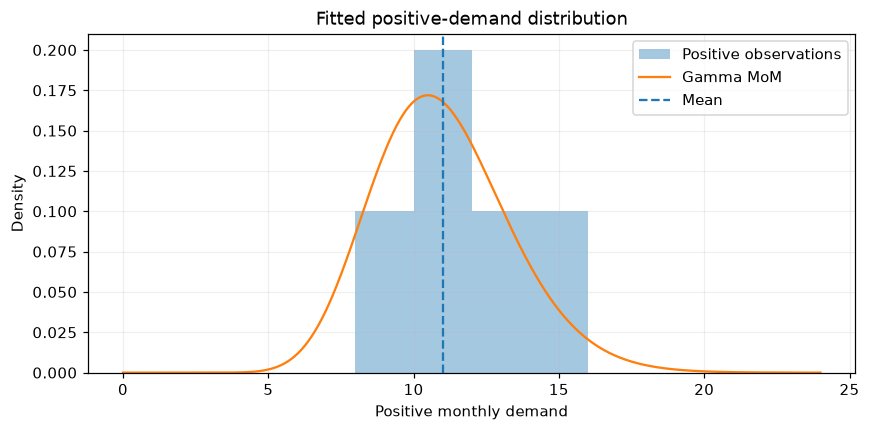

In [5]:
a_mom=mu**2/v
t_mom=v/mu
print(f'Shape={a_mom:.6f}, scale={t_mom:.6f}, rate={1/t_mom:.6f}')
rv=gamma(a_mom,scale=t_mom)
print('Mean, variance:',rv.stats(moments='mv'))
x=np.linspace(0,24,600)
plt.hist(positive,bins=np.arange(6,19,2),density=True,alpha=.4,label='Positive observations'); plt.plot(x,rv.pdf(x),label='Gamma MoM'); plt.axvline(mu,ls='--',label='Mean'); plt.xlabel('Positive monthly demand'); plt.ylabel('Density'); plt.legend(); plt.title('Fitted positive-demand distribution'); plt.show()

## 6. Maximum Likelihood Estimation (MLE)
For independent positive observations, multiply their densities and take logs:
$$\ell=(\alpha-1)\sum\log w_i-\frac{\sum w_i}{\theta}-n\log\Gamma(\alpha)-n\alpha\log\theta$$
Differentiating with respect to scale gives $\hat\theta=\bar w/\alpha$.
Differentiating with respect to shape and substituting scale gives:
$$\log\alpha-\psi(\alpha)=\log\bar w-\frac1n\sum\log w_i$$
where $\psi$ is the digamma function (derivative of log Gamma). Solve numerically; unlike basic Poisson, there is no simple closed-form shape estimate. Fix location to zero so that the model retains its intended positive support.

Right-hand side: 0.02238155708674272
MLE shape, scale: 22.505231002538313 0.4887752540180252


,Method,Shape,Scale,Log likelihood
0,MoM,21.607143,0.509091,-11.226991
1,MLE,22.505231,0.488775,-11.224915


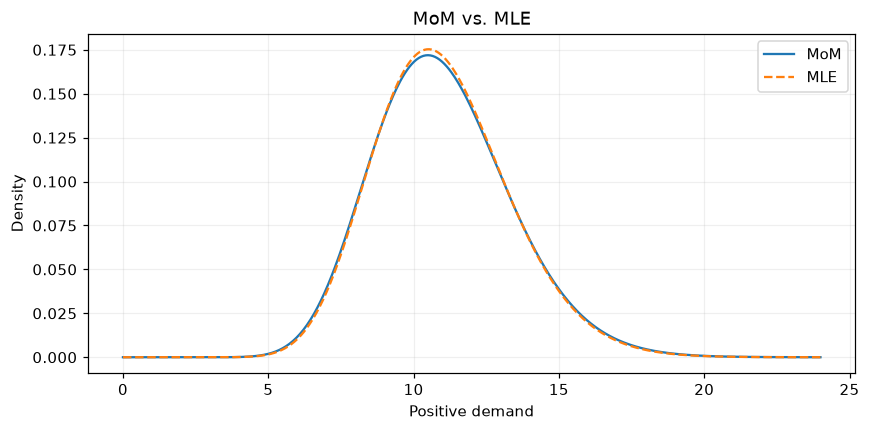

In [6]:
rhs=np.log(mu)-np.log(positive).mean()
a_root=brentq(lambda a:np.log(a)-digamma(a)-rhs,1e-4,1e6)
a_mle,loc,t_mle=gamma.fit(positive,floc=0)
assert np.isclose(a_root,a_mle)
print('Right-hand side:',rhs)
print('MLE shape, scale:',a_mle,t_mle)
display(pd.DataFrame({'Method':['MoM','MLE'],'Shape':[a_mom,a_mle],'Scale':[t_mom,t_mle],'Log likelihood':[rv.logpdf(positive).sum(),gamma.logpdf(positive,a_mle,scale=t_mle).sum()]}))
plt.plot(x,rv.pdf(x),label='MoM'); plt.plot(x,gamma.pdf(x,a_mle,scale=t_mle),ls='--',label='MLE'); plt.xlabel('Positive demand'); plt.ylabel('Density'); plt.title('MoM vs. MLE'); plt.legend(); plt.show()

## 7. CDF, survival function and quantiles
$$F(w)=P(W\le w)=\int_0^w f(t)\,dt$$
$$P(a<W\le b)=F(b)-F(a),\qquad P(W>w)=1-F(w)$$
The quantile $F^{-1}(u)$ is the demand threshold for cumulative probability $u$. We use MoM for the remaining worked examples so the parameter calculations are reproducible by hand. SciPy performs numerical integration/inversion internally.

P(W <= 10)                       0.358017
P(W > 15)                        0.055908
P(10 < W <= 15)                  0.586075
95% positive-demand quantile    15.159704
dtype: float64

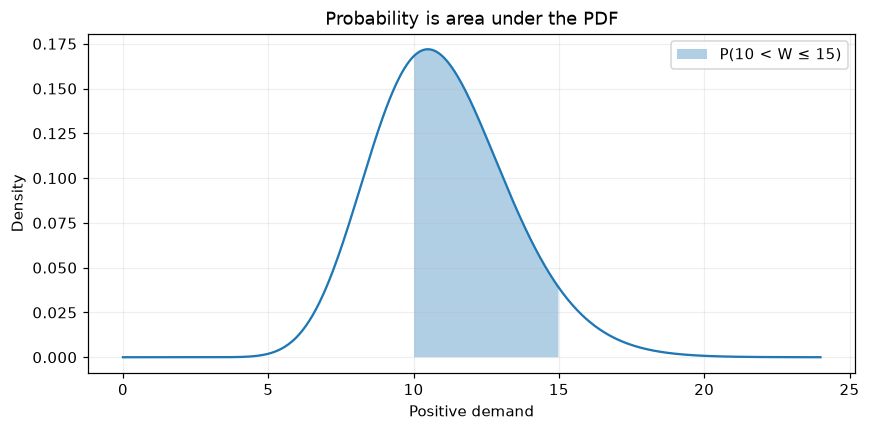

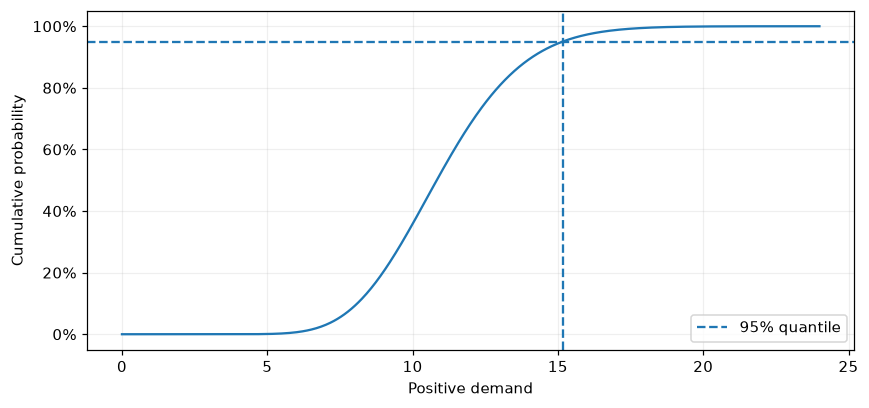

In [7]:
display(pd.Series({'P(W <= 10)':rv.cdf(10),'P(W > 15)':rv.sf(15),'P(10 < W <= 15)':rv.cdf(15)-rv.cdf(10),'95% positive-demand quantile':rv.ppf(.95)}))
plt.plot(x,rv.pdf(x)); mask=(x>=10)&(x<=15); plt.fill_between(x[mask],rv.pdf(x[mask]),alpha=.35,label='P(10 < W ≤ 15)'); plt.xlabel('Positive demand'); plt.ylabel('Density'); plt.legend(); plt.title('Probability is area under the PDF'); plt.show()
plt.plot(x,rv.cdf(x)); plt.axhline(.95,ls='--'); plt.axvline(rv.ppf(.95),ls='--',label='95% quantile'); plt.gca().yaxis.set_major_formatter(PercentFormatter(1)); plt.xlabel('Positive demand'); plt.ylabel('Cumulative probability'); plt.legend(); plt.show()

## 8. Mean, variance, mode and coefficient of variation
$$E[W]=\alpha\theta=11,\quad \operatorname{Var}(W)=\alpha\theta^2=5.6$$
$$\sigma=\sqrt{5.6},\quad \text{mode}=(\alpha-1)\theta,\quad CV^2=1/\alpha$$
Gamma variance is not constrained to equal the mean. For fixed mean, decreasing shape increases dispersion. A Gamma GLM uses the relationship $\operatorname{Var}(W\mid x)=\phi\mu(x)^2$, where $\phi$ is dispersion.

Mean          11.000000
Variance       5.600000
SD             2.366432
Mode          10.490909
CV squared     0.046281
Skewness       0.430260
dtype: float64

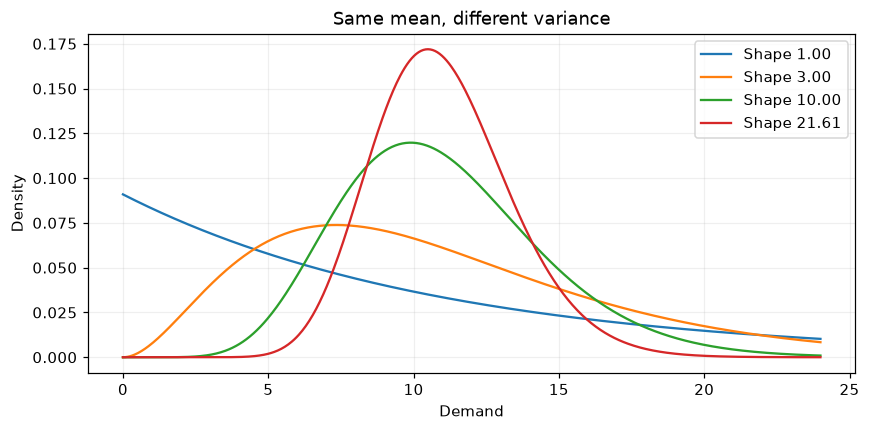

In [8]:
display(pd.Series({'Mean':rv.mean(),'Variance':rv.var(),'SD':rv.std(),'Mode':(a_mom-1)*t_mom,'CV squared':1/a_mom,'Skewness':2/np.sqrt(a_mom)}))
for a in [1,3,10,a_mom]: plt.plot(x,gamma.pdf(x,a,scale=mu/a),label=f'Shape {a:.2f}')
plt.xlabel('Demand'); plt.ylabel('Density'); plt.title('Same mean, different variance'); plt.legend(); plt.show()

## 9. Combine occurrence and positive magnitude: hurdle model
A standalone Gamma distribution cannot explain seven zero months. Introduce $B\sim\operatorname{Bernoulli}(q)$, independently of $W$, and set $Y=BW$.
$$P(Y=0)=1-q=7/12$$
$$F_Y(y)=1-q+qF_W(y),\qquad y\ge0$$
$$E[Y]=q\mu_W$$
By the law of total variance:
$$\operatorname{Var}(Y)=q\sigma_W^2+q(1-q)\mu_W^2$$
This is a Bernoulli–Gamma hurdle model, not a Tweedie distribution. Matching empirical occurrence and conditional first two moments matches the historical monthly population variance by construction; it is not independent validation.

Monthly mean: 4.583333333333334 Monthly variance: 31.74305555555555 Empirical population variance: 31.743055555555557


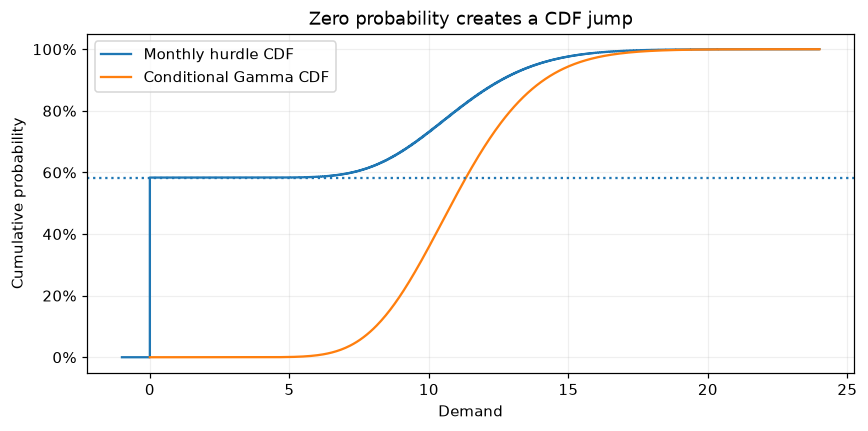

In [9]:
def hurdle_cdf(y):
    y=np.asarray(y)
    return np.where(y<0,0,1-p_occ+p_occ*rv.cdf(y))
def hurdle_ppf(u):
    if not 0<u<1: raise ValueError('u must be between 0 and 1')
    return 0. if u<=1-p_occ else rv.ppf((u-(1-p_occ))/p_occ)
var_y=p_occ*v+p_occ*(1-p_occ)*mu**2
print('Monthly mean:',p_occ*mu,'Monthly variance:',var_y,'Empirical population variance:',demand.var())
plt.step(np.r_[-1,x],hurdle_cdf(np.r_[-1,x]),where='post',label='Monthly hurdle CDF'); plt.plot(x,rv.cdf(x),label='Conditional Gamma CDF'); plt.axhline(1-p_occ,ls=':'); plt.gca().yaxis.set_major_formatter(PercentFormatter(1)); plt.xlabel('Demand'); plt.ylabel('Cumulative probability'); plt.legend(); plt.title('Zero probability creates a CDF jump'); plt.show()

## 10. Forecasting and inventory optimization
For a one-month protection period and target cycle service level $s$:
$$S=\lceil F_Y^{-1}(s)\rceil$$
For $s>1-q$, use the conditional Gamma quantile at $(s-1+q)/q$. At 95%, this is $(0.95-0.583333)/0.416667=0.88$.
Safety stock is $S-E[Y]$ (relative to the protection-period mean). Cycle service level is the probability of no stockout, not the unit fill rate. The calculation assumes all inventory is available at the beginning of the period and no replenishment within it.

For independent months with the same occurrence and magnitude parameters, the number of positive months over $L$ months is Binomial$(L,q)$. Given $j>0$ positive months, total demand is Gamma$(j\alpha,\theta)$. This gives an exact mixture under these assumptions, rather than simply multiplying the one-month quantile by $L$.

Monthly point forecast             4.583333
Six-month expected demand         27.500000
Conditional Gamma 95% quantile    15.159704
Monthly hurdle 95% quantile       13.825033
Required integer stock            14.000000
Safety stock                       9.416667
Model service level                0.955076
Historical coverage                0.916667
dtype: float64

1 months: mean=4.583, stock=14, service=95.508%
3 months: mean=13.750, stock=32, service=95.683%
6 months: mean=27.500, stock=52, service=95.581%


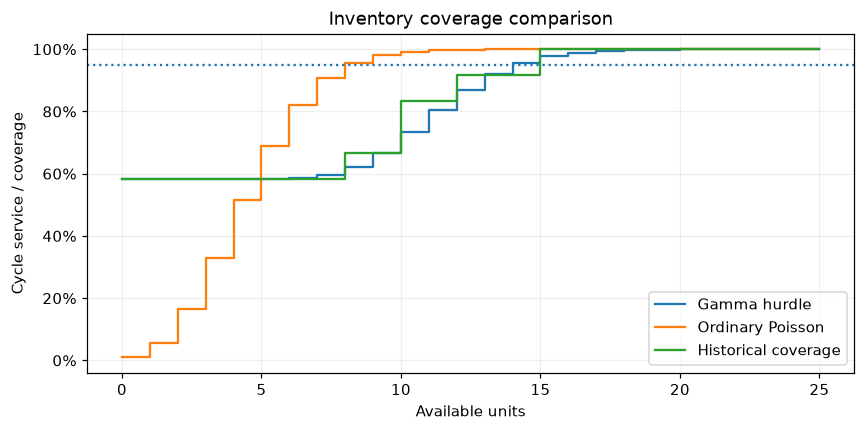

In [10]:
from scipy.stats import binom
s=.95
stock=int(np.ceil(hurdle_ppf(s)))
display(pd.Series({'Monthly point forecast':p_occ*mu,'Six-month expected demand':6*p_occ*mu,'Conditional Gamma 95% quantile':rv.ppf(s),'Monthly hurdle 95% quantile':hurdle_ppf(s),'Required integer stock':stock,'Safety stock':stock-lam,'Model service level':float(hurdle_cdf(stock)),'Historical coverage':np.mean(demand<=stock)}))
def lead_cdf(z,L):
    if z<0:return 0.
    return binom.pmf(0,L,p_occ)+sum(binom.pmf(j,L,p_occ)*gamma.cdf(z,j*a_mom,scale=t_mom) for j in range(1,L+1))
for L in [1,3,6]:
    S=next(i for i in range(1000) if lead_cdf(i,L)>=s)
    print(f'{L} months: mean={L*lam:.3f}, stock={S}, service={lead_cdf(S,L):.3%}')
ks=np.arange(0,26)
plt.step(ks,hurdle_cdf(ks),where='post',label='Gamma hurdle'); plt.step(ks,poisson.cdf(ks,lam),where='post',label='Ordinary Poisson'); plt.step(ks,[np.mean(demand<=i) for i in ks],where='post',label='Historical coverage'); plt.axhline(.95,ls=':'); plt.gca().yaxis.set_major_formatter(PercentFormatter(1)); plt.xlabel('Available units'); plt.ylabel('Cycle service / coverage'); plt.title('Inventory coverage comparison'); plt.legend(); plt.show()

## 11. Gamma regression
A Gamma generalized linear model can use features to forecast positive demand. With log link:
$$\log\mu(x)=\beta_0+\beta_1x,\qquad \mu(x)=e^{\beta_0+\beta_1x}$$
Illustrative normal utilization demand: 8, 10, 12 (mean 10). High utilization: 12, 15, 18 (mean 15). For this binary-feature unregularized model, $\beta_0=\log10$, $\beta_1=\log(15/10)=0.405465$. High utilization increases conditional mean by 50% in this example. A separate occurrence model is needed to forecast all months.

Intercept: 2.3025850926505487 Coefficient: [0.40546511] Predictions: [10. 15.]


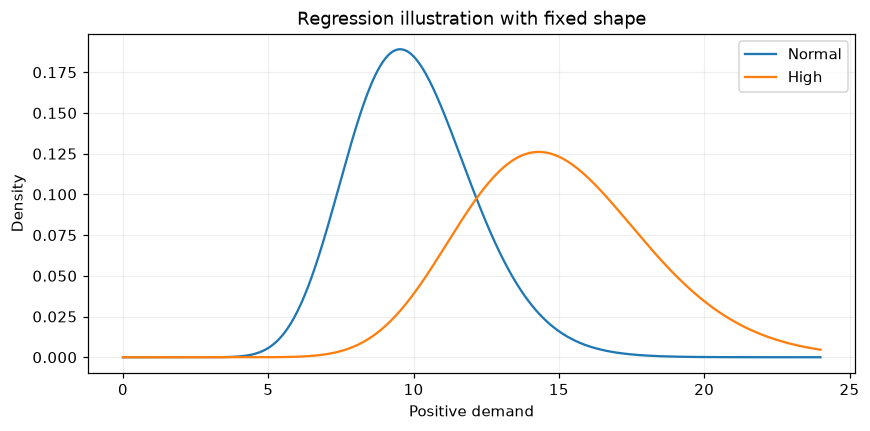

In [11]:
from sklearn.linear_model import GammaRegressor
X=np.array([[0],[0],[0],[1],[1],[1]])
y=np.array([8,10,12,12,15,18])
model=GammaRegressor(alpha=0,max_iter=1000,tol=1e-10).fit(X,y)
print('Intercept:',model.intercept_,'Coefficient:',model.coef_,'Predictions:',model.predict([[0],[1]]))
for label,mean in zip(['Normal','High'],model.predict([[0],[1]])):
    plt.plot(x,gamma.pdf(x,a_mom,scale=mean/a_mom),label=label)
plt.xlabel('Positive demand'); plt.ylabel('Density'); plt.title('Regression illustration with fixed shape'); plt.legend(); plt.show()

## 12. Gamma loss and deviance
For fixed shape, the negative log likelihood terms that depend on predicted mean are proportional to:
$$\mathcal L(y,\mu)=y/\mu+\log\mu$$
Gamma unit deviance:
$$D(y,\mu)=2\left[\frac y\mu-1-\log\left(\frac y\mu\right)\right]$$
Both require positive targets for the Gamma likelihood/deviance; do not replace zeros with arbitrary tiny values merely to fit a Gamma model. In scikit-learn, `alpha` controls regularization, not Gamma shape.

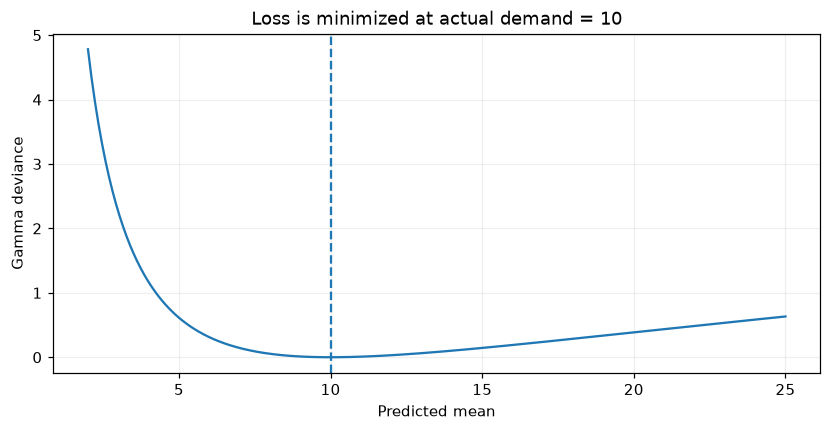

Regression mean Gamma deviance: 0.02721466301350343


In [12]:
from sklearn.metrics import mean_gamma_deviance
pred=np.linspace(2,25,400); actual=10
plt.plot(pred,2*(actual/pred-1-np.log(actual/pred))); plt.axvline(actual,ls='--'); plt.xlabel('Predicted mean'); plt.ylabel('Gamma deviance'); plt.title('Loss is minimized at actual demand = 10'); plt.show()
print('Regression mean Gamma deviance:',mean_gamma_deviance(y,model.predict(X)))

## 13. Connection to Poisson and Tweedie
If $N\sim\operatorname{Poisson}(\nu)$ and independent event sizes $W_i\sim\operatorname{Gamma}(a,t)$, define $Y=\sum_{i=1}^N W_i$.
$$P(Y=0)=e^{-\nu}$$
$$E[Y]=\nu at,\qquad \operatorname{Var}(Y)=\nu(a t^2+(at)^2)$$
Matching the historical zero proportion gives $\nu=-\log(7/12)$. Matching mean gives event size mean $4.583333/\nu$. These are inferred event-level moments, not observed individual order sizes. The positive-month Gamma fit above must not be treated as the individual event-size fit.

For a Tweedie model with mean $\mu$, dispersion $\phi$, and power $1<p<2$:
$$\nu=\frac{\mu^{2-p}}{\phi(2-p)},\quad a=\frac{2-p}{p-1},\quad t=\phi(p-1)\mu^{p-1}$$
This implies $\operatorname{Var}(Y)=\phi\mu^p$. Gamma itself corresponds to power 2; Poisson to power 1 (unit dispersion).

Implied event rate: 0.5389965007326871 Implied mean event size: 8.503456566235513
Simulated monthly mean: 4.5899105598902885 Zero fraction: 0.58273


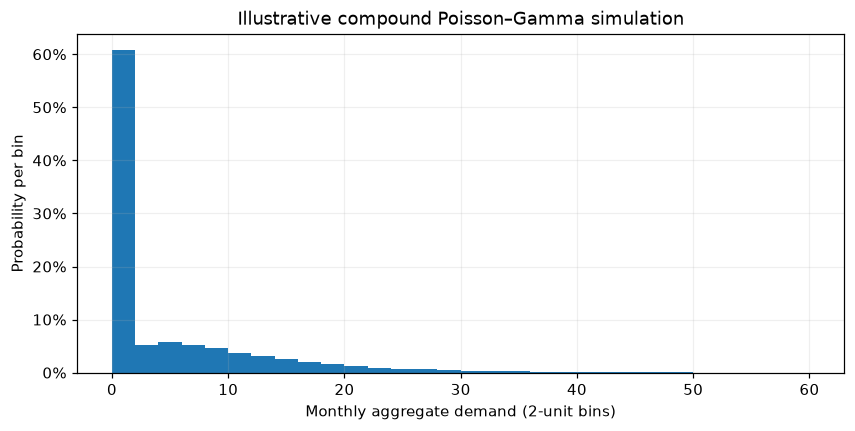

In [13]:
nu=-np.log(1-p_occ)
event_mean=lam/nu
print('Implied event rate:',nu,'Implied mean event size:',event_mean)
# Illustrative event shape, NOT estimated from the observed months
rng=np.random.default_rng(42); N=rng.poisson(nu,100000); event_shape=2
sim=np.zeros(len(N)); mask=N>0
sim[mask]=rng.gamma(N[mask]*event_shape,event_mean/event_shape)
print('Simulated monthly mean:',sim.mean(),'Zero fraction:',np.mean(sim==0))
plt.hist(sim,bins=np.arange(0,61,2),weights=np.ones(len(sim))/len(sim)); plt.gca().yaxis.set_major_formatter(PercentFormatter(1)); plt.xlabel('Monthly aggregate demand (2-unit bins)'); plt.ylabel('Probability per bin'); plt.title('Illustrative compound Poisson–Gamma simulation'); plt.show()

## 14. Model comparison and selection
| Model | Zeros | Positive support | Key limitation |
|---|---|---|---|
| Poisson | Yes | Integer | Equidispersion |
| Gamma | No atom at zero | Continuous | Cannot model occurrence alone |
| Bernoulli–Gamma | Yes | Continuous | Two components; not exact for count demand |
| Negative Binomial | Yes | Integer | May still miss excess zeros |
| Tweedie ($1<p<2$) | Yes | Continuous | More complex estimation |

For the original SKU, only five positive observations are available. Gamma fit is illustrative and uncertain; a count hurdle model may be more appropriate for integer units. Use rolling-origin validation of mean forecasts, occurrence calibration, quantile coverage and inventory costs. Do not compare raw continuous density likelihood to discrete probability likelihood without a common observation model.

## 15. Practice questions
1. Shape = 4 and scale = 3. What are the mean and variance?
2. Shape = 1. Which familiar distribution results?
3. Can ordinary Gamma assign 58.33% probability to exactly zero?
4. Positive demand mean = 10 and population variance = 20. Find MoM shape and scale.
5. Occurrence probability = 0.4 and conditional mean = 10. Find expected monthly demand.
6. If $q=0.4$, what conditional percentile corresponds to the monthly 95th percentile?

### Answer key
1. Mean 12, variance 36. 2. Exponential. 3. No. 4. Shape 5, scale 2. 5. 4 units. 6. $(0.95-0.60)/0.40=0.875$, or 87.5th percentile.

## 16. Revision formulas and final results
| Concept | Formula |
|---|---|
| Gamma mean | $\alpha\theta$ |
| Gamma variance | $\alpha\theta^2$ |
| MoM shape | $\bar w^2/m_2$ |
| MoM scale | $m_2/\bar w$ |
| Rate | $1/\theta$ |
| Hurdle mean | $q\mu_W$ |
| Hurdle variance | $q\sigma_W^2+q(1-q)\mu_W^2$ |
| Gamma regression | $\mu=e^{x^T\beta}$ |
| Compound Poisson mean | $\nu E[W]$ |

**Remember:** Gamma answers how large positive demand is; a separate occurrence model or compound process answers how often it occurs.

References for further study: [SciPy Gamma](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html), [GammaRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.GammaRegressor.html), McCullagh and Nelder, *Generalized Linear Models*.

**Masterclass progress: 7/12. Next: Part 8 — Negative Binomial Distribution.**

## Appendix — Interactive Gamma explorer
Change shape and scale to see the density and CDF-based probability. Run the following cell in a widget-compatible Jupyter environment; static sensitivity plots above remain available without widgets.

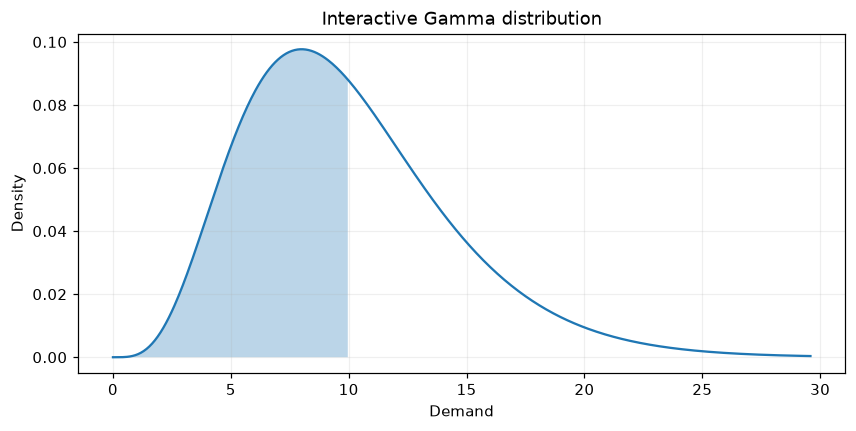

Mean=10.000; variance=20.000; P(W ≤ 10)=55.95%; 95% quantile=18.307


In [14]:
def explore(shape=5.,scale=2.,threshold=10.):
    r=gamma(shape,scale=scale)
    xx=np.linspace(.001,max(r.ppf(.999),threshold*1.1),500)
    plt.plot(xx,r.pdf(xx)); plt.fill_between(xx,r.pdf(xx),where=xx<=threshold,alpha=.3); plt.xlabel('Demand'); plt.ylabel('Density'); plt.title('Interactive Gamma distribution'); plt.show()
    print(f'Mean={r.mean():.3f}; variance={r.var():.3f}; P(W ≤ {threshold:g})={r.cdf(threshold):.2%}; 95% quantile={r.ppf(.95):.3f}')
explore()

In [15]:
# Optional live sliders (run in Jupyter)
from ipywidgets import interact, FloatSlider
interact(explore, shape=FloatSlider(value=5,min=.2,max=35,step=.2), scale=FloatSlider(value=2,min=.1,max=8,step=.1), threshold=FloatSlider(value=10,min=0,max=50,step=.5));

ModuleNotFoundError: No module named 'ipywidgets'